# Study 2: environmental and economic feasibility audit

- This notebook checks whether the current environment creates meaningful trade-offs between development, mitigation costs, and pollution before we change the reward function.
- Gross emissions are `8 + 0.10 × EDI + 0.001 × EDI²`. Mitigation prevents new emissions and it does not remove accumulated pollution.

## 1. Set up the audit

- The six policies are deterministic and all regions follow the same rule. Each policy uses the same 100 environment seeds.
- The threshold rule develops until EDI 70 when it can afford development. After that, it chooses mitigation based on its own pollution and the currency available at the start of the step.
- An episode fails when any region reaches pollution 100; otherwise it ends at the configured step limit.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from study_2_economic_sustainability.config import EnvironmentConfig
from study_2_economic_sustainability.environment import EconomicSustainabilityEnvironment

In [1]:
SEEDS = tuple(range(10_000, 10_100))
POLICIES = ("save", "develop_when_affordable", "low", "medium", "high", "threshold")
POLICY_LABELS = {"save": "Save", "develop_when_affordable": "Develop when affordable", "low": "Always low", "medium": "Always medium", "high": "Always high", "threshold": "Threshold rule"}
ACTION_NAMES = ("save", "develop", "low", "medium", "high")
PERSISTENCE_VALUES = (0.80, 0.90, 0.95)
HIGH_CAPACITY_VALUES = (16, 20, 30)
base_config = EnvironmentConfig()
print(f"{len(POLICIES)} policies × {len(SEEDS)} shared environment seeds")
print(f"Episode limit: {base_config.episode_steps} | failure threshold: {base_config.failure_threshold}")

6 policies × 100 shared environment seeds
Episode limit: 200 | failure threshold: 100.0


## 2. Define the policies and episode measures

- The environment charges action costs before adding that step's income. We record both if the starting balance can pay for high mitigation and whether income alone covers its price.
- The episode summary tracks failure, episode length, final EDI and currency, mean and peak pollution, income, spending, and action shares.

In [2]:
def choose_actions(policy, environment):
    actions = []
    for region in range(4):
        edi = environment.development_indices[region]
        balance = environment.currency_balances[region]
        pollution = environment.pollution_loads[region]
        costs = environment.config.action_costs

        if policy == "save":
            action = 0
        elif policy == "develop_when_affordable":
            action = 1 if edi < 100 and balance >= costs[1] else 0
        elif policy in ("low", "medium", "high"):
            action = {"low": 2, "medium": 3, "high": 4}[policy]
        elif policy == "threshold":
            if edi < 70 and balance >= costs[1]:
                action = 1
            elif pollution >= 35 and balance >= costs[4]:
                action = 4
            elif pollution >= 25 and balance >= costs[3]:
                action = 3
            elif pollution >= 15 and balance >= costs[2]:
                action = 2
            else:
                action = 0
        else:
            raise ValueError(f"Unknown policy: {policy}")
        actions.append(action)
    return actions

In [ ]:
def create_episode_totals():
    return {
        "pollution_values": [],
        "income": 0.0,
        "spending": 0.0,
        "high_affordable": 0,
        "income_covers_high": 0,
        "region_steps": 0,
        "action_counts": [0, 0, 0, 0, 0],
    }


In [ ]:
def make_trace_row(policy, seed, step, edi, action, info, region):
    if edi < 40:
        edi_band = "low"
    elif edi < 70:
        edi_band = "middle"
    else:
        edi_band = "high"

    return {
        "policy": policy,
        "seed": seed,
        "step": step,
        "starting_edi": edi,
        "edi_band": edi_band,
        "income": info["income"][region],
        "spending": info["costs_paid"][region],
        "currency": info["currency_balances"][region],
        "action": ACTION_NAMES[action],
    }


In [ ]:
def record_episode_step(
    totals, actions, starting_balances, starting_edi, info, config,
    policy, seed, step, trace, save_trace
):
    totals["pollution_values"].extend(info["pollution_loads"])
    totals["income"] += sum(info["income"])
    totals["spending"] += sum(info["costs_paid"])
    totals["region_steps"] += 4

    for region, action in enumerate(actions):
        totals["action_counts"][action] += 1
        if starting_balances[region] >= config.action_costs[4]:
            totals["high_affordable"] += 1
        if info["income"][region] >= config.action_costs[4]:
            totals["income_covers_high"] += 1
        if save_trace:
            trace_row = make_trace_row(
                policy, seed, step, starting_edi[region], action, info, region
            )
            trace.append(trace_row)


In [ ]:
def summarize_episode(environment, policy, seed, config, totals, failed):
    pollution_values = totals["pollution_values"]
    region_steps = totals["region_steps"]
    row = {
        "policy": policy,
        "seed": seed,
        "persistence": config.persistence,
        "high_capacity": config.mitigation_capacity[4],
        "steps": environment.step_count,
        "failed": failed,
        "final_mean_edi": sum(environment.development_indices) / 4,
        "final_mean_pollution": sum(environment.pollution_loads) / 4,
        "mean_pollution": sum(pollution_values) / len(pollution_values),
        "max_pollution": max(pollution_values),
        "final_mean_currency": sum(environment.currency_balances) / 4,
        "income": totals["income"],
        "spending": totals["spending"],
        "high_affordable_fraction": totals["high_affordable"] / region_steps,
        "income_covers_high_fraction": totals["income_covers_high"] / region_steps,
    }

    for action, count in enumerate(totals["action_counts"]):
        row[f"{ACTION_NAMES[action]}_fraction"] = count / region_steps
    return row


In [ ]:
def run_episode(policy, seed, persistence=None, high_capacity=None, save_trace=False):
    config = EnvironmentConfig()
    if persistence is not None:
        config.persistence = persistence
    if high_capacity is not None:
        config.mitigation_capacity = (*config.mitigation_capacity[:4], high_capacity)

    environment = EconomicSustainabilityEnvironment(config=config)
    environment.reset(seed)
    totals = create_episode_totals()
    trace = []

    while True:
        actions = choose_actions(policy, environment)
        starting_balances = environment.currency_balances
        starting_edi = environment.development_indices
        result = environment.step(actions)
        observations, rewards, terminated, truncated, info = result
        record_episode_step(
            totals, actions, starting_balances, starting_edi, info,
            config, policy, seed, environment.step_count, trace, save_trace
        )

        if terminated or truncated:
            break

    row = summarize_episode(environment, policy, seed, config, totals, terminated)
    return row, trace


## 3. Baseline under current settings

In [3]:
baseline_rows = []
baseline_trace_rows = []
for policy in POLICIES:
    for seed in SEEDS:
        row, trace = run_episode(policy, seed, save_trace=True)
        baseline_rows.append(row)
        baseline_trace_rows.extend(trace)

baseline_episodes = pd.DataFrame(baseline_rows)
baseline_summary = baseline_episodes.groupby("policy")[["failed", "steps", "final_mean_edi", "mean_pollution", "max_pollution", "final_mean_currency", "income", "spending"]].mean().rename(columns={"failed": "failure_rate"}).reindex(POLICIES).round(2)
display(baseline_summary)

,failure_rate,steps,final_mean_edi,mean_pollution,max_pollution,final_mean_currency,income,spending
policy,,,,,,,,
save,0.0,200.00,0.00,55.08,56.00,4543.36,16000.00,0.00
develop_when_affordable,1.0,11.24,61.08,61.43,104.24,126.16,1703.20,3372.00
low,0.0,200.00,0.00,20.78,21.00,2543.36,16000.00,8000.00
medium,0.0,200.00,0.00,5.45,15.67,32.54,16000.00,18043.25
high,0.0,200.00,0.00,30.33,37.77,45.98,16000.00,17989.50
threshold,0.0,200.00,70.00,34.50,81.23,5293.87,42703.35,23701.30


## 4. Economic feasibility

- Income is `20 + 0.5 × EDI`; high mitigation costs 50. Income alone covers that price from EDI 60 onward.
- The environment checks the current balance before adding income, so a region may earn enough over time but still be unable to buy high mitigation on a particular step.

In [8]:
economic_summary = baseline_episodes.groupby("policy")[["high_affordable_fraction", "income_covers_high_fraction", "high_fraction", "final_mean_currency"]].mean().reindex(POLICIES).round(3)
display(economic_summary)

,high_affordable_fraction,income_covers_high_fraction,high_fraction,final_mean_currency
policy,,,,
save,1.000,0.000,0.00,4543.358
develop_when_affordable,0.956,0.152,0.00,126.156
low,1.000,0.000,0.00,2543.358
medium,0.496,0.000,0.00,32.545
high,0.450,0.000,1.00,45.982
threshold,0.991,0.911,0.04,5293.870


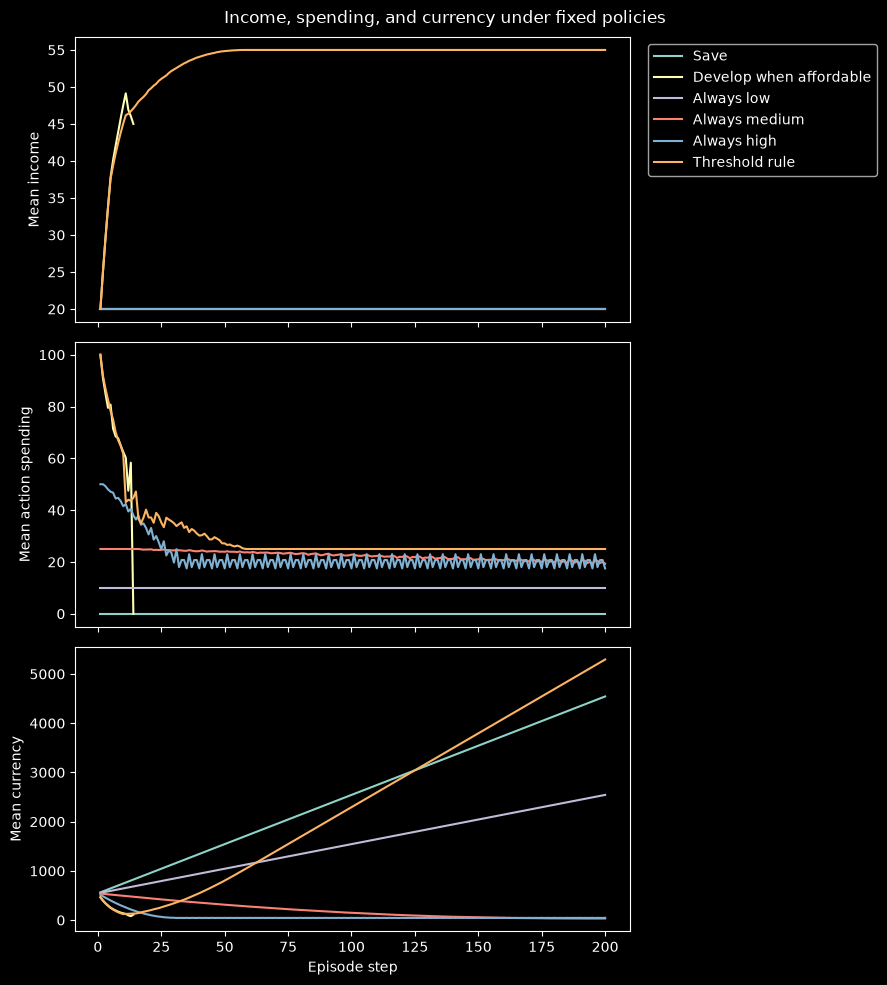

In [9]:
trace_summary = pd.DataFrame(baseline_trace_rows).groupby(["policy", "step"])[["income", "spending", "currency"]].mean().reset_index()
fig, axes = plt.subplots(3, 1, figsize=(9, 10), sharex=True)
for policy in POLICIES:
    rows = trace_summary[trace_summary["policy"] == policy]
    axes[0].plot(rows["step"], rows["income"], label=POLICY_LABELS[policy])
    axes[1].plot(rows["step"], rows["spending"], label=POLICY_LABELS[policy])
    axes[2].plot(rows["step"], rows["currency"], label=POLICY_LABELS[policy])
axes[0].set_ylabel("Mean income")
axes[1].set_ylabel("Mean action spending")
axes[2].set_ylabel("Mean currency")
axes[2].set_xlabel("Episode step")
axes[0].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("Income, spending, and currency under fixed policies")
plt.tight_layout()
plt.show()

## 5. Pollution persistence sensitivity

- Compare persistence 0.80, 0.90, and 0.95 while leaving emissions, mitigation, costs, and spillover unchanged. Higher persistence means more pollution from the previous step remains.

In [10]:
persistence_rows = []
for persistence in PERSISTENCE_VALUES:
    for policy in POLICIES:
        for seed in SEEDS:
            row, trace = run_episode(policy, seed, persistence=persistence)
            persistence_rows.append(row)
persistence_episodes = pd.DataFrame(persistence_rows)
persistence_summary = persistence_episodes.groupby(["persistence", "policy"])[["failed", "mean_pollution", "max_pollution", "final_mean_edi", "final_mean_currency"]].mean().rename(columns={"failed": "failure_rate"}).round(2)
display(persistence_summary)

failure_rate  mean_pollution  \
persistence policy                                                  
0.80        develop_when_affordable          1.00           61.43   
            high                             0.00           30.33   
            low                              0.00           20.78   
            medium                           0.00            5.45   
            save                             0.00           55.08   
            threshold                        0.00           34.50   
0.90        develop_when_affordable          1.00           61.12   
            high                             0.00           59.04   
            low                              0.00           40.56   
            medium                           0.00           10.41   
            save                             1.00           73.07   
            threshold                        0.84           50.17   
0.95        develop_when_affordable          1.00           60.95   
            high                             1.00           36.89   
            low                              0.00           76.97   
            medium                           0.00           18.89   
            save                             1.00           64.61   
            threshold                        0.91           53.03   

                                     max_pollution  final_mean_edi  \
persistence policy                                                   
0.80        develop_when_affordable         104.24           61.08   
            high                             37.77            0.00   
            low                              21.00            0.00   
            medium                           15.67            0.00   
            save                             56.00            0.00   
            threshold                        81.23           70.00   
0.90        develop_when_affordable         107.66           51.51   
            high                             71.18            0.00   
            low                              42.00            0.00   
            medium                           26.31            0.00   
            save                            100.84            0.00   
            threshold                       101.93           52.88   
0.95        develop_when_affordable         108.60           47.78   
            high                            101.87            0.00   
            low                              84.00            0.00   
            medium                           47.50            0.00   
            save                            102.28            0.00   
            threshold                       105.39           48.25   

                                     final_mean_currency  
persistence policy                                        
0.80        develop_when_affordable               126.16  
            high                                   45.98  
            low                                  2543.36  
            medium                                 32.54  
            save                                 4543.36  
            threshold                            5293.87  
0.90        develop_when_affordable               171.53  
            high                                   45.98  
            low                                  2543.36  
            medium                                 32.54  
            save                                  963.36  
            threshold                             562.55  
0.95        develop_when_affordable               195.39  
            high                                   48.53  
            low                                  2543.36  
            medium                                 32.54  
            save                                  763.36  
            threshold                             283.62

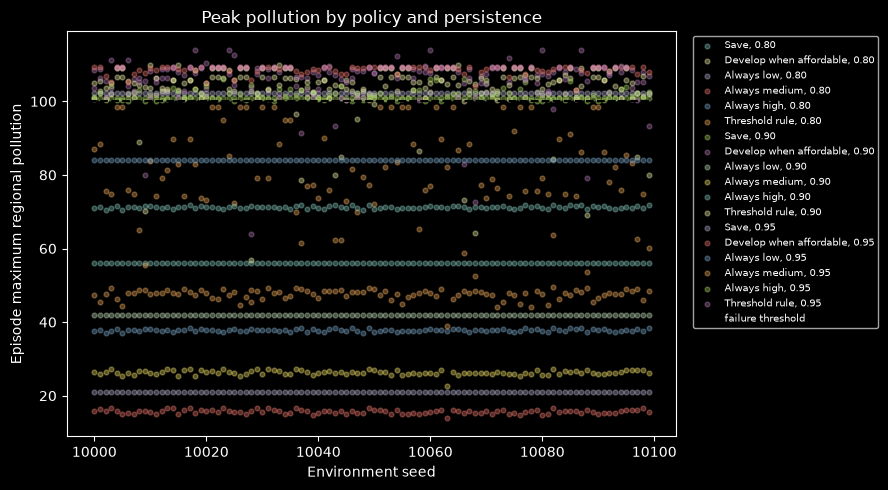

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
for persistence in PERSISTENCE_VALUES:
    for policy in POLICIES:
        rows = persistence_episodes[(persistence_episodes["persistence"] == persistence) & (persistence_episodes["policy"] == policy)]
        ax.scatter(rows["seed"], rows["max_pollution"], s=12, alpha=0.35, label=f"{POLICY_LABELS[policy]}, {persistence:.2f}")
ax.axhline(base_config.failure_threshold, color="black", linestyle="--", label="failure threshold")
ax.set(xlabel="Environment seed", ylabel="Episode maximum regional pollution", title="Peak pollution by policy and persistence")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
plt.tight_layout()
plt.show()

## 6. Mitigation capacity sensitivity

- Keep low and medium capacities, all prices, and spillover at current values. Vary only high mitigation capacity: 16, 20, and 30. Combined with three persistence values, this gives nine configurations.

In [12]:
capacity_rows = []
for persistence in PERSISTENCE_VALUES:
    for high_capacity in HIGH_CAPACITY_VALUES:
        for policy in POLICIES:
            for seed in SEEDS:
                row, trace = run_episode(policy, seed, persistence=persistence, high_capacity=high_capacity)
                capacity_rows.append(row)
capacity_episodes = pd.DataFrame(capacity_rows)
capacity_summary = capacity_episodes.groupby(["persistence", "high_capacity", "policy"])[["failed", "mean_pollution", "max_pollution", "final_mean_edi", "final_mean_currency", "spending", "high_fraction"]].mean().rename(columns={"failed": "failure_rate"}).round(2)
display(capacity_summary)

failure_rate  \
persistence high_capacity policy                                  
0.80        16            develop_when_affordable          1.00   
                          high                             0.00   
                          low                              0.00   
                          medium                           0.00   
                          save                             0.00   
                          threshold                        0.00   
            20            develop_when_affordable          1.00   
                          high                             0.00   
                          low                              0.00   
                          medium                           0.00   
                          save                             0.00   
                          threshold                        0.00   
            30            develop_when_affordable          1.00   
                          high                             0.00   
                          low                              0.00   
                          medium                           0.00   
                          save                             0.00   
                          threshold                        0.00   
0.90        16            develop_when_affordable          1.00   
                          high                             0.00   
                          low                              0.00   
                          medium                           0.00   
                          save                             1.00   
                          threshold                        0.84   
            20            develop_when_affordable          1.00   
                          high                             0.00   
                          low                              0.00   
                          medium                           0.00   
                          save                             1.00   
                          threshold                        0.84   
            30            develop_when_affordable          1.00   
                          high                             0.00   
                          low                              0.00   
                          medium                           0.00   
                          save                             1.00   
                          threshold                        0.84   
0.95        16            develop_when_affordable          1.00   
                          high                             1.00   
                          low                              0.00   
                          medium                           0.00   
                          save                             1.00   
                          threshold                        0.91   
            20            develop_when_affordable          1.00   
                          high                             1.00   
                          low                              0.00   
                          medium                           0.00   
                          save                             1.00   
                          threshold                        0.91   
            30            develop_when_affordable          1.00   
                          high                             1.00   
                          low                              0.00   
                          medium                           0.00   
                          save                             1.00   
                          threshold                        0.91   

                                                   mean_pollution  \
persistence high_capacity policy                                    
0.80        16            develop_when_affordable           61.43   
                          high                              30.33   
                      

In [ ]:
failure_matrix = capacity_episodes.groupby(["persistence", "high_capacity", "policy"])["failed"].mean().unstack("high_capacity")
fig, axes = plt.subplots(1, len(PERSISTENCE_VALUES), figsize=(12, 4), sharey=True)
for ax, persistence in zip(axes, PERSISTENCE_VALUES):
    values = failure_matrix.loc[persistence].reindex(POLICIES)
    image = ax.imshow(values, vmin=0, vmax=1, cmap="Reds", aspect="auto")
    ax.set_title(f"Persistence {persistence:.2f}")
    ax.set_xticks(range(len(HIGH_CAPACITY_VALUES)), HIGH_CAPACITY_VALUES)
    policy_labels = []
    for name in POLICIES:
        policy_labels.append(POLICY_LABELS[name])
    ax.set_yticks(range(len(POLICIES)), policy_labels)
    ax.set_xlabel("High mitigation capacity")
    for row_index in range(len(POLICIES)):
        for column_index in range(len(HIGH_CAPACITY_VALUES)):
            ax.text(column_index, row_index, f"{values.iloc[row_index, column_index]:.0%}", ha="center", va="center")
axes[0].set_ylabel("Policy")
fig.colorbar(image, ax=axes, label="Failure rate", shrink=0.8)
fig.suptitle("Failure rate by persistence and high mitigation capacity")
plt.show()


In [7]:
def gross_emissions(edi):
    return base_config.emissions_base + base_config.emissions_edi_linear * edi + base_config.emissions_edi_quadratic * edi ** 2

remaining_rows = []
for high_capacity in HIGH_CAPACITY_VALUES:
    for edi in (0, 40, 70, 100):
        gross = gross_emissions(edi)
        remaining_rows.append({"high_capacity": high_capacity, "edi": edi, "gross_emissions": gross, "remaining_emissions": max(0, gross - high_capacity)})
display(pd.DataFrame(remaining_rows).set_index(["high_capacity", "edi"]).round(2))

gross_emissions  remaining_emissions
high_capacity edi                                      
16            0                8.0                  0.0
              40              13.6                  0.0
              70              19.9                  3.9
              100             28.0                 12.0
20            0                8.0                  0.0
              40              13.6                  0.0
              70              19.9                  0.0
              100             28.0                  8.0
30            0                8.0                  0.0
              40              13.6                  0.0
              70              19.9                  0.0
              100             28.0                  0.0

## 7. Decision checklist

After running the audit, use the tables and plots to answer:

- Can poor environmental management reach failure? Can effective mitigation prevent or reduce it?
- Does development increase environmental pressure?
- Does mitigation create a meaningful financial trade-off, or can income sustain high mitigation?
- Is failure avoidable for reasonable policies?
- Does spillover keep coordination between regions relevant?
- Do these fixed policies already produce meaningful behavior without changing rewards?

Keep coefficients fixed while interpreting this audit. If no setting creates both environmental risk and a controllable path, record that finding before changing the reward function.